# 01 - Análise exploratória (EDA)

Primeira etapa do pipeline (`eda -> prepare -> train`). Explora o dataset bruto *Default of Credit Card Clients* (UCI 350) e fundamenta as decisões de preparação e modelagem.

A lógica vive em `src/credit_monitoring/eda.py`; o mesmo código roda no estágio `eda` do `dvc.yaml`. Aqui as saídas vão para uma pasta temporária para não alterar as saídas rastreadas pelo DVC.

In [1]:
import json
import tempfile
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from credit_monitoring.config import load_config
from credit_monitoring.data.loading import default_raw_path, load_raw
from credit_monitoring.eda import run_eda

pd.options.display.float_format = "{:,.3f}".format

config = load_config()
raw_csv = default_raw_path(config)
raw = load_raw(raw_csv, config)
target = config["dataset"]["canonical_target"]

output_dir = Path(tempfile.mkdtemp(prefix="eda_"))
summary = run_eda(
    raw_csv,
    config,
    figures_dir=output_dir / "figures",
    summary_path=output_dir / "eda_summary.json",
)


def show(name):
    display(Image(filename=output_dir / "figures" / name))

## 1. Visão geral e qualidade

O CSV tem uma linha inicial `X1..X23;Y` descartada na leitura (`header=1`); a coluna alvo é renomeada para `default_payment_next_month`.

In [2]:
quality = {
    key: summary[key]
    for key in [
        "rows",
        "columns",
        "null_values",
        "duplicated_rows",
        "duplicated_ids",
        "non_numeric_columns",
        "age_min",
        "age_max",
        "limit_bal_min",
        "limit_bal_max",
    ]
}
display(pd.Series(quality, name="valor").to_frame())
display(raw.head())
display(raw.describe().T)

,valor
rows,30000
columns,25
null_values,0
duplicated_rows,0
duplicated_ids,0
non_numeric_columns,[]
age_min,21
age_max,79
limit_bal_min,10000
limit_bal_max,1000000


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default_payment_next_month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


,count,mean,std,min,25%,50%,75%,max
ID,"30,000.000","15,000.500","8,660.398",1.000,"7,500.750","15,000.500","22,500.250","30,000.000"
LIMIT_BAL,"30,000.000","167,484.323","129,747.662","10,000.000","50,000.000","140,000.000","240,000.000","1,000,000.000"
SEX,"30,000.000",1.604,0.489,1.000,1.000,2.000,2.000,2.000
EDUCATION,"30,000.000",1.853,0.790,0.000,1.000,2.000,2.000,6.000
MARRIAGE,"30,000.000",1.552,0.522,0.000,1.000,2.000,2.000,3.000
AGE,"30,000.000",35.486,9.218,21.000,28.000,34.000,41.000,79.000
PAY_0,"30,000.000",-0.017,1.124,-2.000,-1.000,0.000,0.000,8.000
PAY_2,"30,000.000",-0.134,1.197,-2.000,-1.000,0.000,0.000,8.000
PAY_3,"30,000.000",-0.166,1.197,-2.000,-1.000,0.000,0.000,8.000
PAY_4,"30,000.000",-0.221,1.169,-2.000,-1.000,0.000,0.000,8.000


## 2. Variável alvo

                            clientes  proporcao
default_payment_next_month                     
0                              23364      0.779
1                               6636      0.221


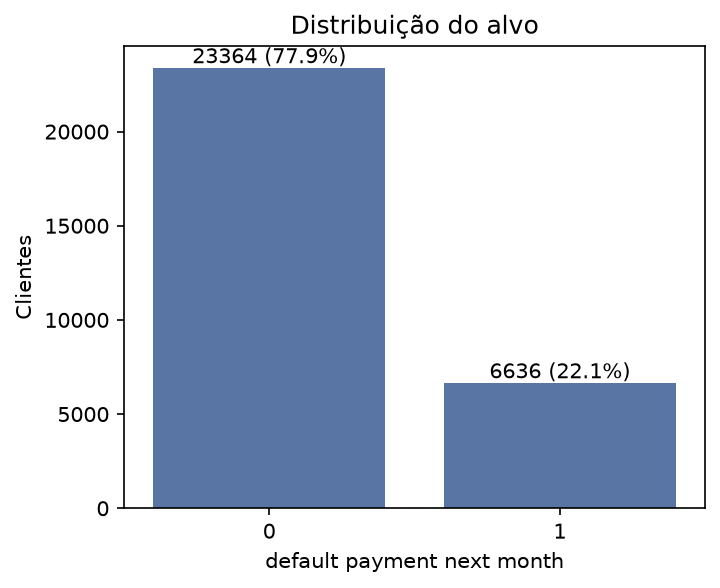

In [3]:
print(raw[target].value_counts().rename("clientes").to_frame().assign(proporcao=raw[target].value_counts(normalize=True)))
show("01_target_distribution.png")

## 3. Variáveis categóricas e idade

Códigos fora da documentação (`EDUCATION` 0/5/6, `MARRIAGE` 0) são apenas reportados, não recodificados.

{
  "SEX": {},
  "EDUCATION": {
    "0": 14,
    "5": 280,
    "6": 51
  },
  "MARRIAGE": {
    "0": 54
  },
  "PAY": {
    "-2": 24415,
    "0": 95919
  }
}


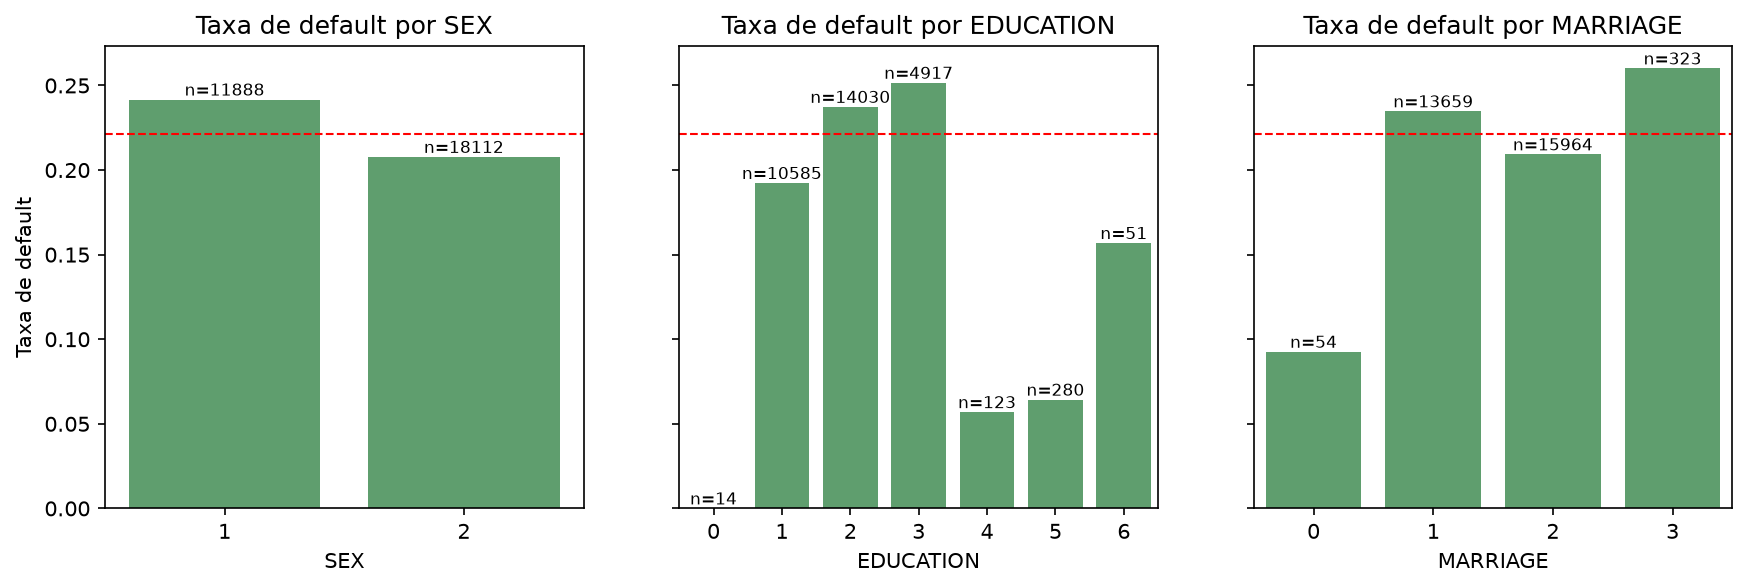

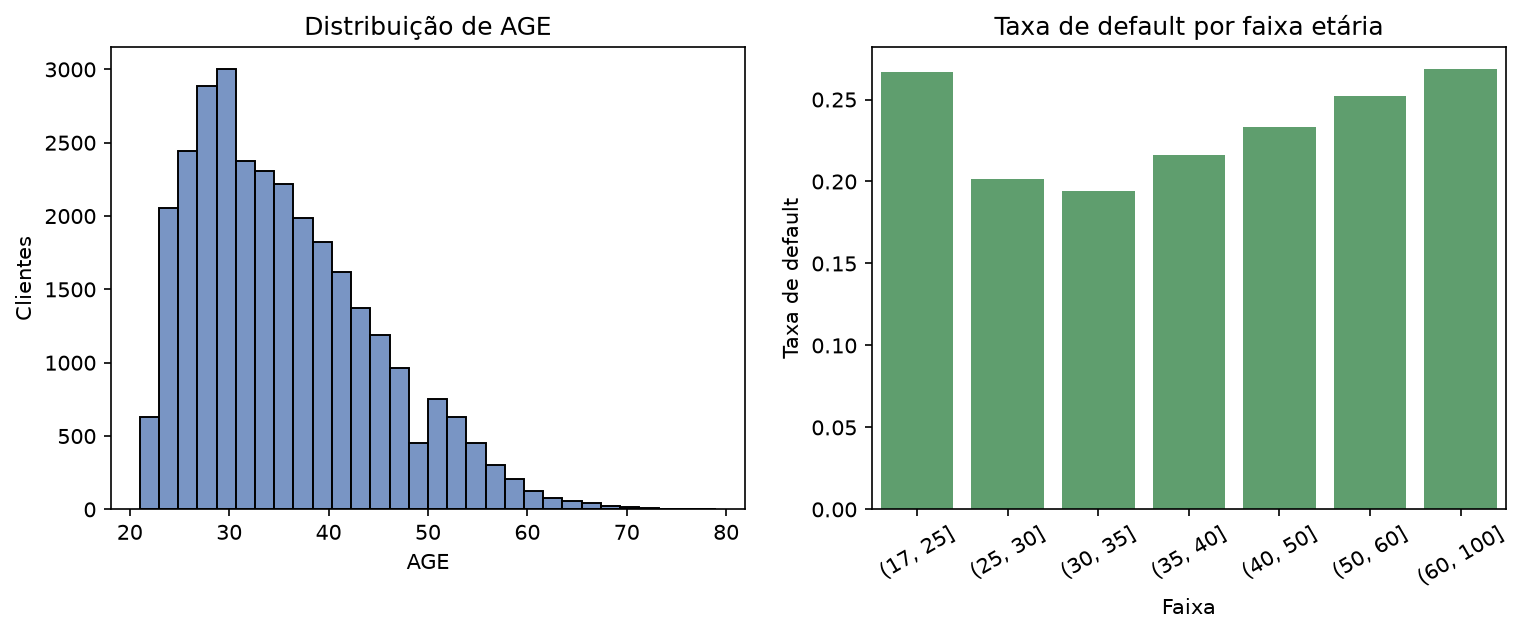

In [4]:
print(json.dumps(summary["undocumented_codes"], indent=2))
show("02_categorical_default_rate.png")
show("03_age.png")

## 4. Histórico de pagamento (`PAY_*`)

A documentação prevê -1 (pago em dia) e 1 a 9 (meses de atraso), mas os dados trazem também -2 e 0.

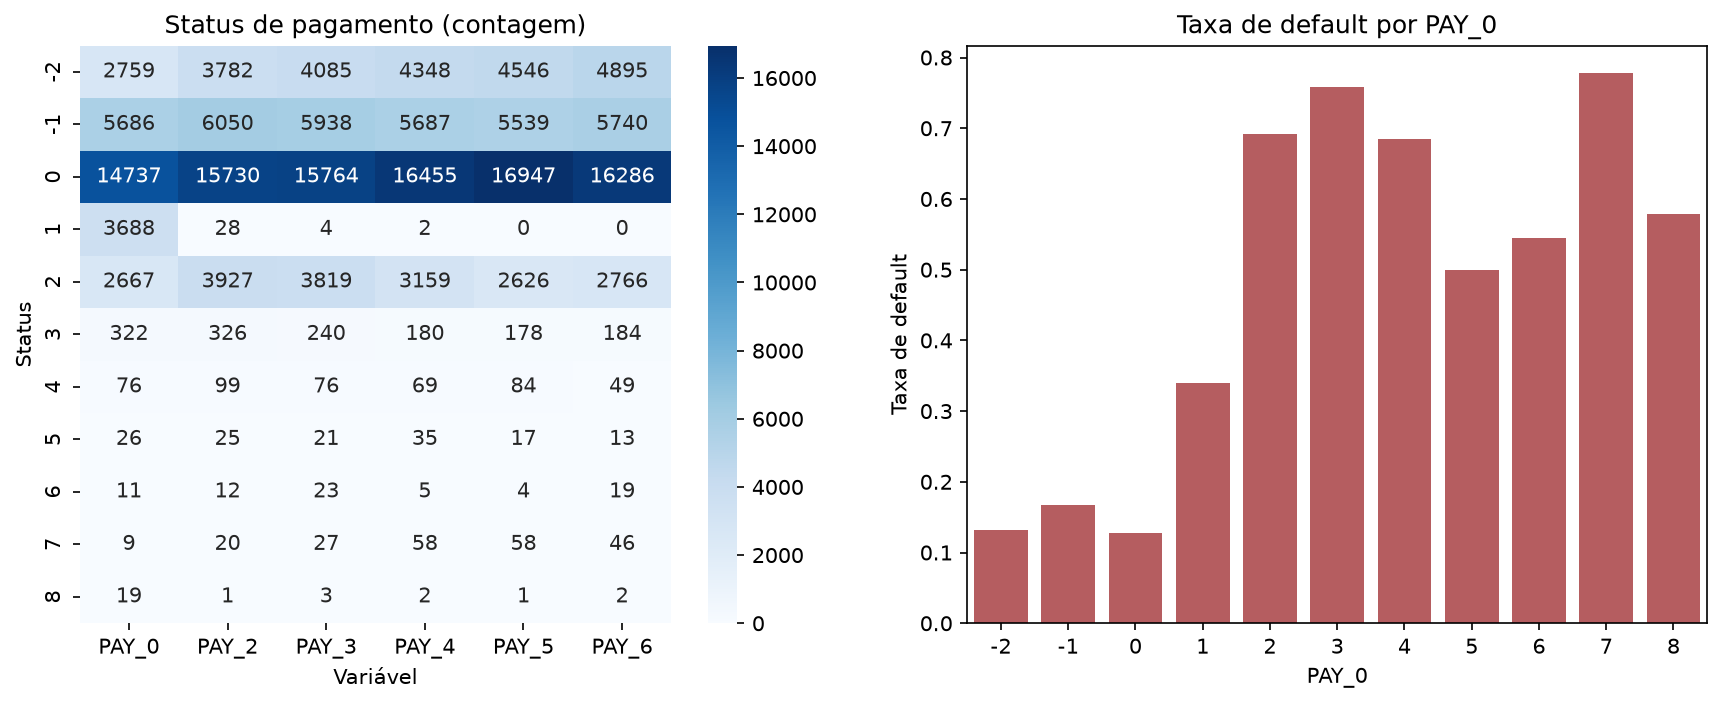

In [5]:
show("04_pay_status.png")

## 5. Valores monetários

`LIMIT_BAL`, `BILL_AMT1..6` e `PAY_AMT1..6` têm cauda longa; `BILL_AMT*` contém valores negativos (crédito na fatura).

BILL_AMT negativos: 3932


,outliers (IQR)
LIMIT_BAL,167
BILL_AMT1,2400
BILL_AMT2,2395
BILL_AMT3,2469
BILL_AMT4,2622
BILL_AMT5,2725
BILL_AMT6,2693
PAY_AMT1,2745
PAY_AMT2,2714
PAY_AMT3,2598


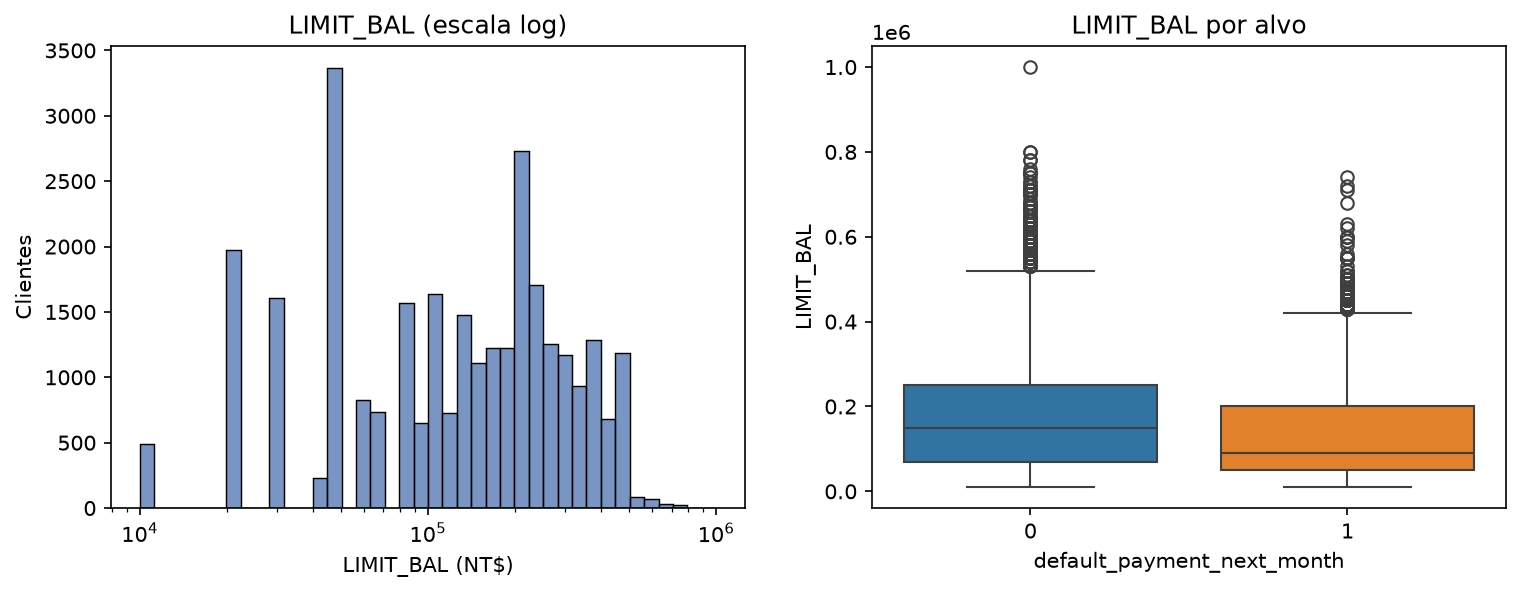

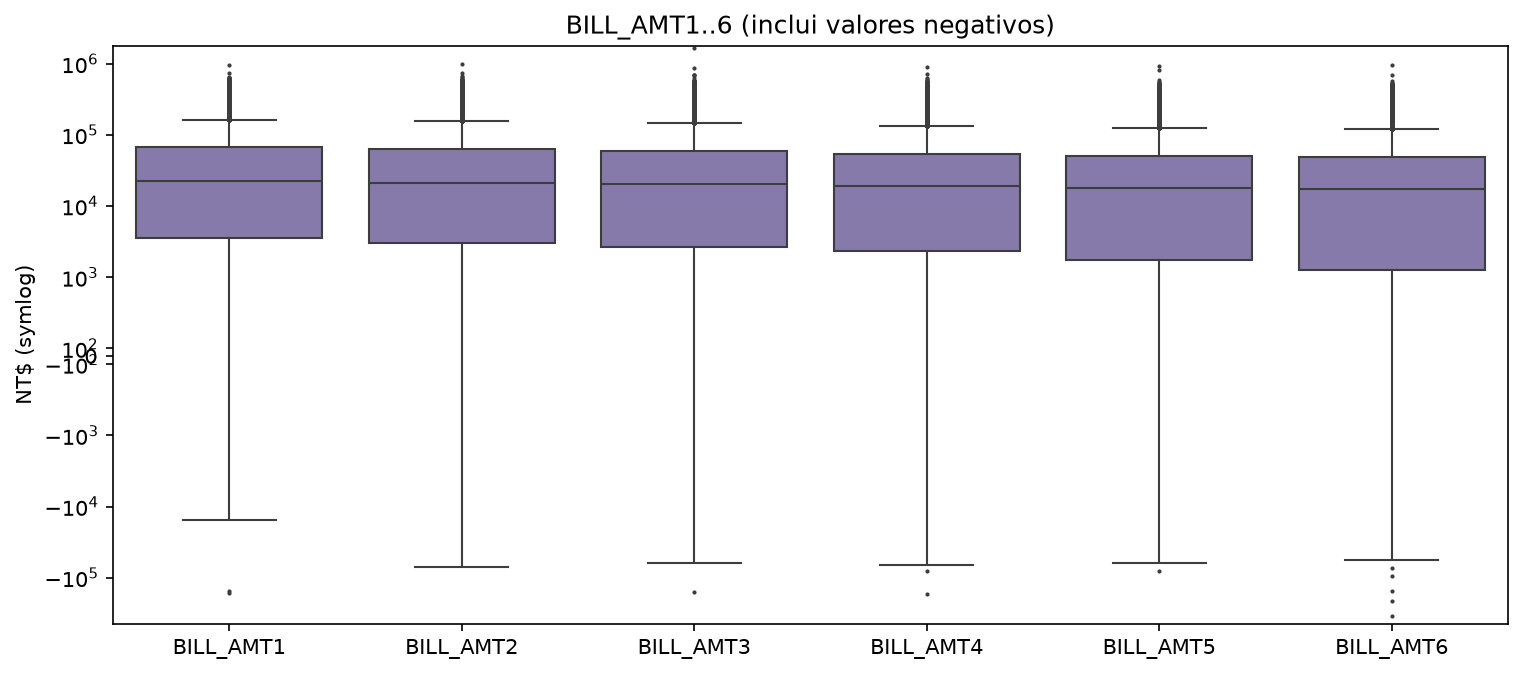

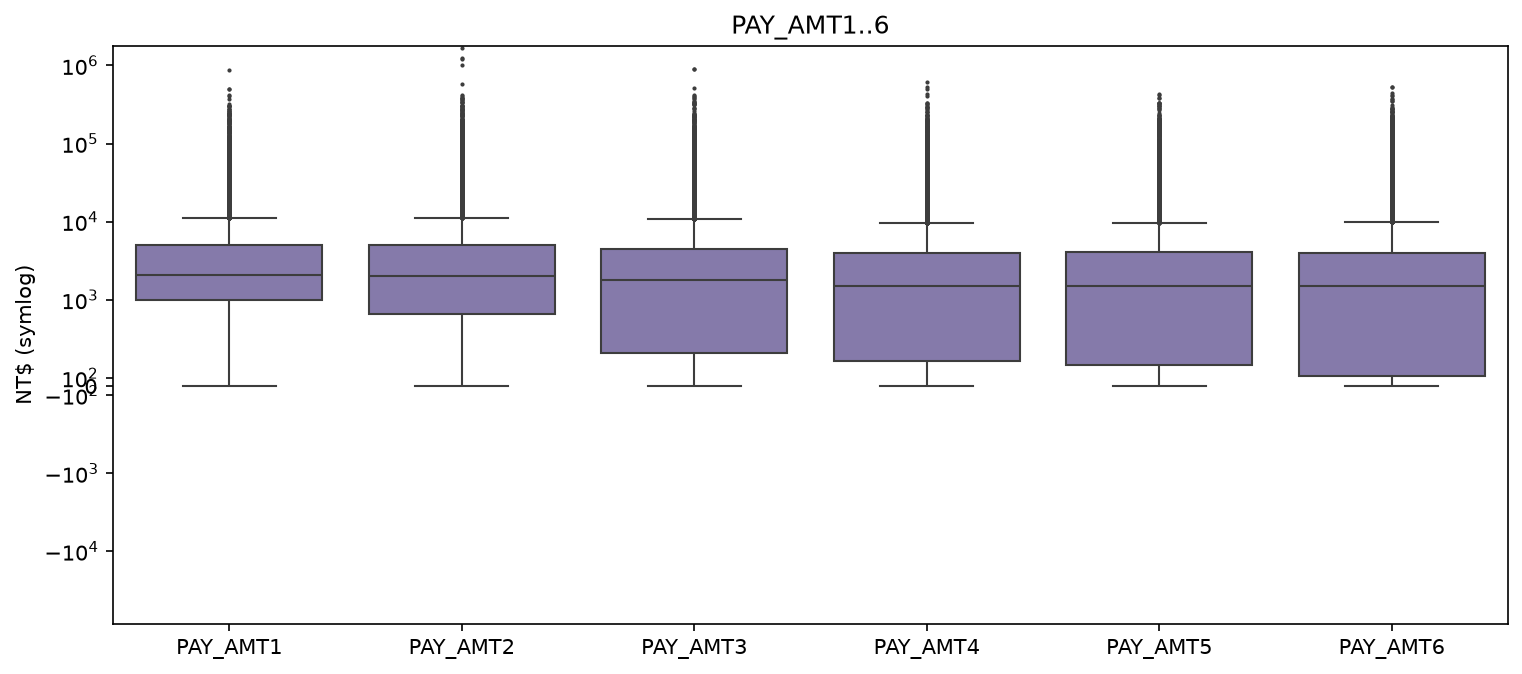

In [6]:
print("BILL_AMT negativos:", summary["negative_bill_amt_values"])
display(pd.Series(summary["iqr_outliers"], name="outliers (IQR)").to_frame())
show("05_limit_bal.png")
show("06_bill_amt.png")
show("07_pay_amt.png")

## 6. Correlações

,pearson
PAY_0,0.325
PAY_2,0.264
PAY_3,0.235
PAY_4,0.217
PAY_5,0.204
PAY_6,0.187
LIMIT_BAL,-0.153
PAY_AMT1,-0.073
PAY_AMT2,-0.059
PAY_AMT4,-0.057


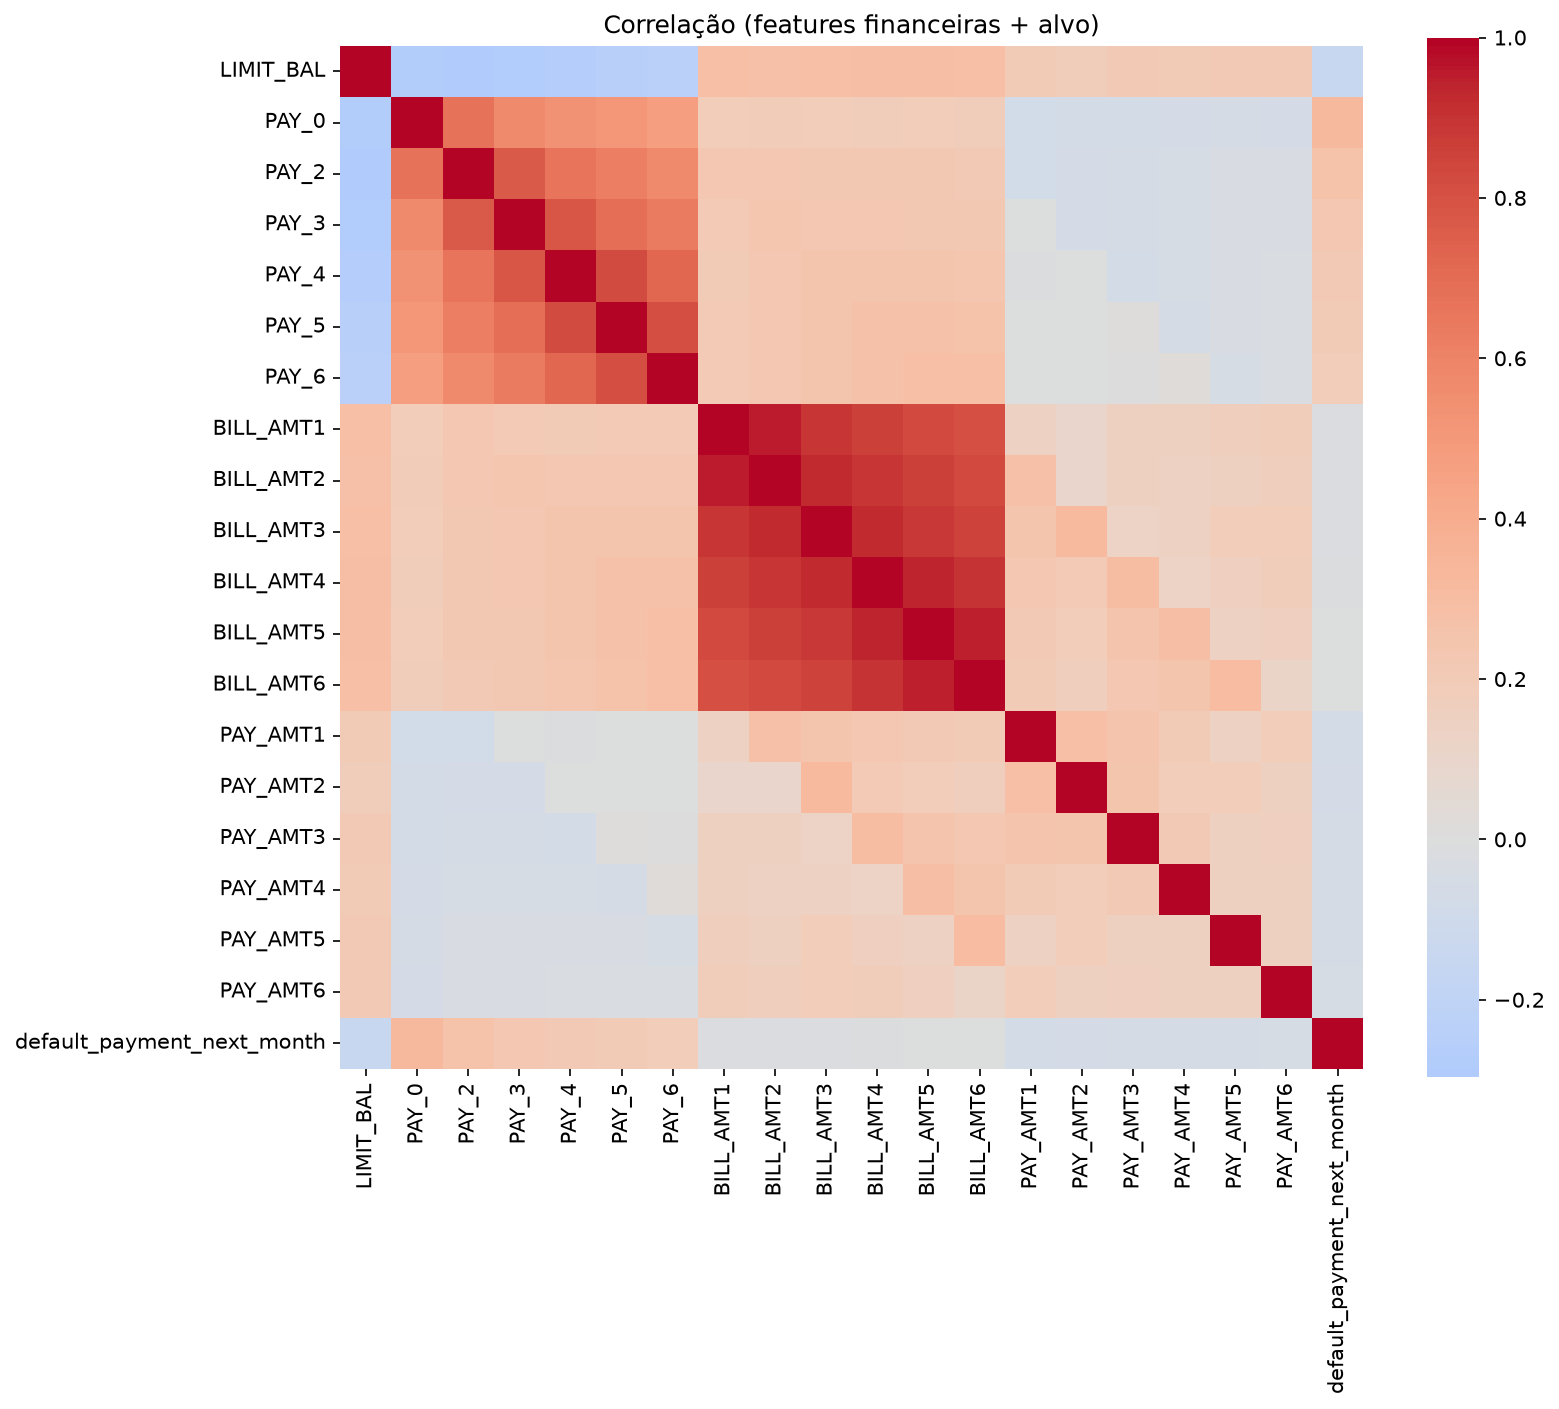

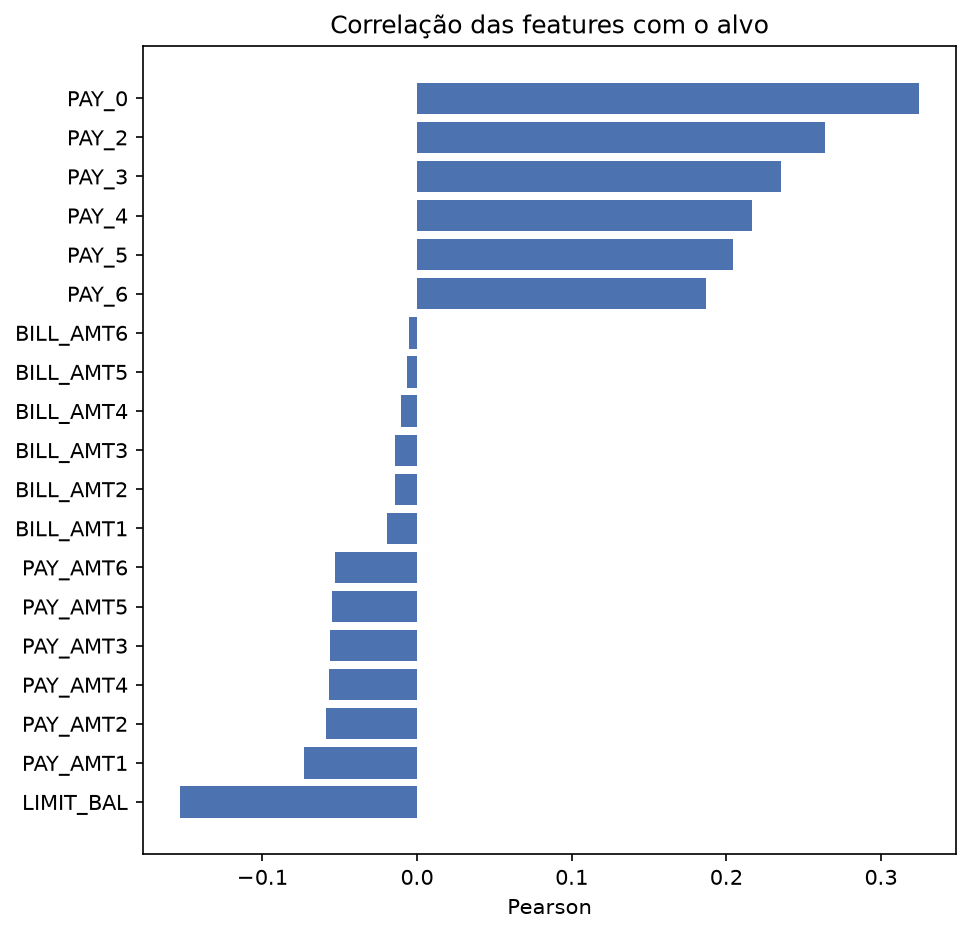

In [7]:
display(pd.Series(summary["top_target_correlations"], name="pearson").sort_values(key=abs, ascending=False).to_frame())
show("08_correlation_heatmap.png")
show("09_target_correlation.png")

## 7. Conclusões e decisões para as próximas etapas

**Achados**
- 30.000 linhas, sem nulos, sem duplicados e sem `ID` repetido; idade de 21 a 79 e `LIMIT_BAL` sempre positivo.
- Alvo desbalanceado: cerca de 22,1% de inadimplentes.
- `PAY_0` é a variável mais correlacionada com o alvo (~0,32); atrasos recentes pesam mais que antigos. `LIMIT_BAL` tem correlação negativa (~-0,15).
- Códigos não documentados: `EDUCATION` 0/5/6 e `MARRIAGE` 0 (poucas linhas) e `PAY_*` com -2 e 0 (muito frequentes).
- Cerca de 3,9 mil valores negativos em `BILL_AMT*` e milhares de outliers por IQR nas colunas monetárias.

**Decisões**
- Preparação remove apenas linhas estruturalmente inválidas (nulos, `ID` duplicado, alvo fora de {0,1}, `LIMIT_BAL` <= 0, idade fora de 18-100); nenhuma recodificação e nenhuma remoção de outliers.
- Split estratificado 70/15/15 pelo alvo, seed 42.
- Desbalanceamento tratado com `class_weight` nos modelos; seleção por ROC-AUC na validação.
- `SEX`, `EDUCATION`, `MARRIAGE` e `AGE` ficam fora do modelo (auditoria de viés na governança); são usadas as 19 features financeiras.
- A Regressão Logística usa `StandardScaler` por causa da escala e da cauda longa dos valores monetários.